id: notebooks/02_instrument.ipynb

antenna types and primary beams, dish transfer function, B210 receiver and sensitivity, arrays and baselines, selector

<!-- notebooks/02_instrument.ipynb -- instrument (Interferosim 0.3.2) -->
# 02 – Instrument: antennas, receiver, array

---
  DI Erich Schubert, 07925151
  


This notebook shows the package `interferosim.instrument`: the selectable **antenna types** (horn, parabolic dish, Yagi), the **receiver** (Ettus USRP B210) and the **array** of stations with its baselines. All parameters come from the configuration files in `configs/`:

| Directory | Content |
|---|---|
| `configs/antennas/` | `horn_15dbi.toml`, `dish_3m.toml`, `yagi.toml` (key `type` selects the class) |
| `configs/receivers/` | `b210.toml` – system temperature, bandwidth, sample rate, channels |
| `configs/sites/` | site Wilhelmsburg, the two stations of the AAS6 simulation, two horns 10 m apart |

Relations used (documentation, chapter *Radio Astronomical Fundamentals*):
$A_\mathrm{eff} = G\lambda^2/4\pi$, Gaussian main lobe $\Omega_A = 1.133\,\theta_\mathrm{HPBW}^2 = 4\pi/G$, $\mathrm{SEFD} = 2kT_\mathrm{sys}/A_\mathrm{eff}$, noise of one visibility $\sigma = \sqrt{\mathrm{SEFD}_1\mathrm{SEFD}_2}/\sqrt{2B\tau}$.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import LINES, HI_21CM, OH_1665, C_LIGHT
from interferosim.instrument import Antenna, Receiver, Array, ParabolicDish
from interferosim.plotting import plot_beams, plot_array
from interferosim.sky import SkyModel

CFG = Path("..") / "configs"
ANTENNAS = {p.stem: Antenna.from_toml(p) for p in sorted((CFG / "antennas").glob("*.toml"))}
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
list(ANTENNAS)

['dish_3m', 'horn_15dbi', 'yagi']

## 1. Antenna types

Key figures at the HI line (1420.406 MHz) and the OH main line (1665.402 MHz), together with the SEFD with the B210 ($T_\mathrm{sys} = 120$ K). The dish keeps its effective area, so its gain rises with frequency; horn and Yagi are defined by their gain (the Yagi values are typical example values, see `yagi.toml`).

In [2]:
print(f"{'antenna':<24s} {'f [MHz]':>9s} {'G [dBi]':>8s} {'A_eff [m2]':>11s} {'HPBW [deg]':>11s} {'SEFD [Jy]':>11s}")
for a in ANTENNAS.values():
    for f in (HI_21CM, OH_1665):
        s = a.summary(f)
        print(f"{a.name:<24s} {f/1e6:9.3f} {s['gain_dbi']:8.2f} {s['a_eff_m2']:11.3f} "
              f"{s['hpbw_deg']:11.2f} {b210.sefd_jy(a, f):11.0f}")

antenna                    f [MHz]  G [dBi]  A_eff [m2]  HPBW [deg]   SEFD [Jy]
Dish 3 m                  1420.406    30.78       4.241        4.84       78129
Dish 3 m                  1665.402    32.16       4.241        4.13       78129
Horn 15 dBi               1420.406    15.00       0.112       33.93     2955887
Horn 15 dBi               1665.402    15.00       0.082       33.93     4063508
Yagi 13 el. (example)     1420.406    15.00       0.112       33.93     2955887
Yagi 13 el. (example)     1665.402    15.00       0.082       33.93     4063508


The primary beams: horn and Yagi are modelled as Gaussian main lobes derived from the gain, the dish as the Airy pattern of the equivalent uniformly illuminated aperture $d_\mathrm{eff} = 1.02\,D/k$ (same HPBW $k\lambda/D$, with side lobes). The bars mark the HPBW. Horn and Yagi coincide here, because both have 15 dBi (the Yagi example was chosen with the same gain; with the data of a real antenna they will differ).

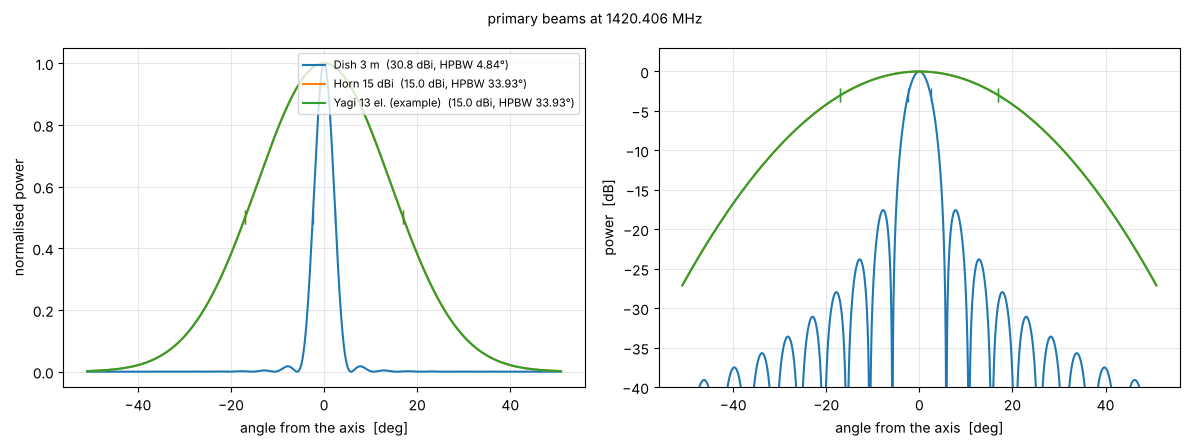

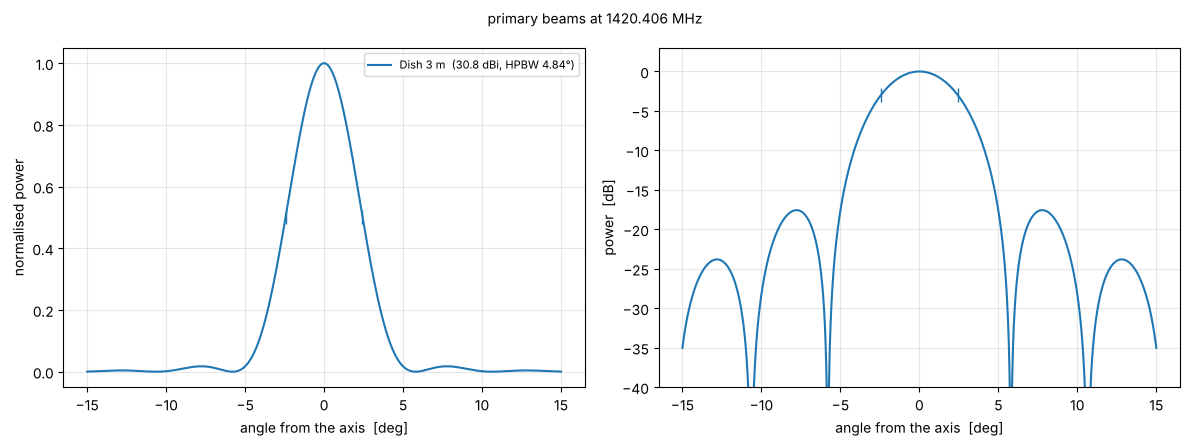

In [3]:
fig, axes = plot_beams(ANTENNAS.values())
plt.show()
fig, axes = plot_beams([ANTENNAS["dish_3m"]], theta_max_deg=15)
plt.show()

## 2. Transfer function of the dish

A single dish passes spatial frequencies only up to a cut-off. With tapered illumination the beam is wider than $\lambda/D$, so the effective cut-off is $u_\mathrm{cut} = d_\mathrm{eff}/\lambda = 1.02\,D/(k\lambda)$ and not $u_\mathrm{max} = D/\lambda$ (`aas6sim`, `u_cut_eff`). An interferometer baseline of length $b$ measures the spatial frequency $b/\lambda$ – far beyond the single dish.

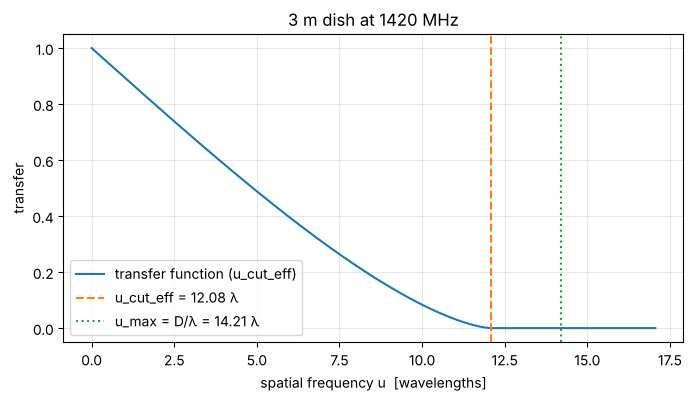

In [4]:
dish = ANTENNAS["dish_3m"]
u = np.linspace(0, 1.2 * dish.u_max(), 500)
plt.figure(figsize=(8, 4))
plt.plot(u, dish.otf(u), label="transfer function (u_cut_eff)")
plt.axvline(dish.u_cut_eff(), color="C1", ls="--", label=f"u_cut_eff = {dish.u_cut_eff():.2f} λ")
plt.axvline(dish.u_max(), color="C2", ls=":", label=f"u_max = D/λ = {dish.u_max():.2f} λ")
plt.xlabel("spatial frequency u  [wavelengths]"); plt.ylabel("transfer")
plt.title("3 m dish at 1420 MHz"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 3. Receiver and sensitivity

The B210 profile (notebook B). The table gives the noise of one visibility (real or imaginary part) for both arrays and the expected signal-to-noise ratio $|V|/\sigma$ for the sky models of notebook 01, each at its transit (east–west baseline: $u = b/\lambda$, $v = 0$; source in the beam centre, total bandwidth 2 MHz).

In [5]:
b210

Receiver(name='Ettus USRP B210', t_sys_k=120.0, bandwidth_hz=2000000.0, sample_rate_sps=2000000.0, rx_channels=2, bits=16, agc=False, dc_offset_correction=False, iq_balance_correction=False, clock_source='internal', center_freq_hz=1420405751.768, rx_gain_db=None, sample_format='sc16', time_source='none', external_lna=True, freq_min_hz=70000000.0, freq_max_hz=6000000000.0, adc_bits=12, max_sample_rate_sps=61440000.0, max_sample_rate_2ch_sps=30720000.0, max_bandwidth_hz=56000000.0, max_bandwidth_2ch_hz=30720000.0, noise_figure_db=8.0, rx_gain_range_db=[0.0, 76.0], iip3_dbm=-20.0, adc_sfdr_dbc=78.0, freq_accuracy_ppm=2.0, freq_accuracy_gpsdo_unlocked_ppb=75.0, freq_accuracy_gpsdo_locked_ppb=1.0, pps_accuracy_ns=50.0, host_interface='USB 3.0 (USB 2.0 compatible)', fpga='Xilinx Spartan-6 XC6SLX150', extra={})

### B210 device profile

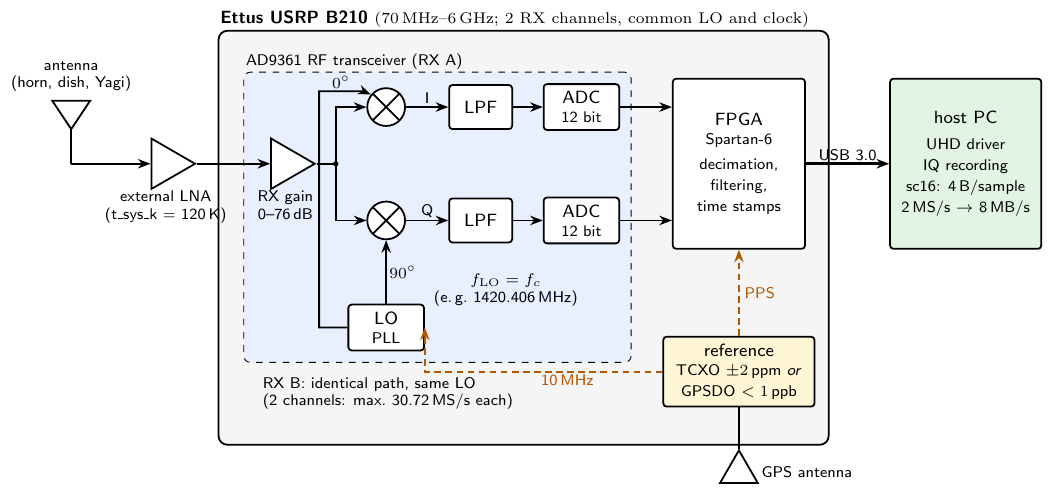

*Receive path of one station.* The sky signal from the antenna is amplified by an **external LNA** – the system temperature of 120 K used in the notebooks is only possible with it, the B210 alone has a noise figure of up to 8 dB (≈ 1540 K). Inside the B210 the AD9361 amplifies (0–76 dB), mixes with the local oscillator to complex baseband (I and Q), filters and digitises with 12 bits; the FPGA decimates and time-stamps the samples, which reach the host over USB 3.0. Both RX channels share LO and clock. The LO and the sample clock follow the **reference**: the internal TCXO (±2 ppm) or a GPS-disciplined oscillator (< 1 ppb, with PPS) – the decisive choice for the VLB interferometer (notebook 00). Figure: `docs/images/b210_blockdiagram.tex` (TikZ).

The profile `configs/receivers/b210.toml` holds the operating settings of notebook B and the data-sheet values of the device; `b210_gpsdo.toml` (one station with GPSDO) and `b210_aas6_sim.toml` (settings of the AAS6 simulation) build on it with `base = "b210"`.

In [6]:
print("device data (data sheet):")
for key, unit, scale in (("freq_min_hz", "MHz", 1e-6), ("freq_max_hz", "MHz", 1e-6), ("adc_bits", "bit", 1),
                         ("max_sample_rate_sps", "MS/s", 1e-6), ("max_sample_rate_2ch_sps", "MS/s", 1e-6),
                         ("max_bandwidth_hz", "MHz", 1e-6), ("max_bandwidth_2ch_hz", "MHz", 1e-6),
                         ("noise_figure_db", "dB", 1), ("iip3_dbm", "dBm", 1), ("adc_sfdr_dbc", "dBc", 1),
                         ("freq_accuracy_ppm", "ppm", 1), ("freq_accuracy_gpsdo_unlocked_ppb", "ppb", 1),
                         ("freq_accuracy_gpsdo_locked_ppb", "ppb", 1), ("pps_accuracy_ns", "ns", 1)):
    print(f"  {key:<34s} {getattr(b210, key) * scale:10.6g} {unit}")
print(f"  {'rx_gain_range_db':<34s} {b210.rx_gain_range_db} dB")
print(f"  {'host_interface':<34s} {b210.host_interface}")
print(f"  {'fpga':<34s} {b210.fpga}")
print(f"\nreceiver noise temperature from NF: {b210.receiver_noise_temperature_k():.0f} K "
      f"(t_sys_k = {b210.t_sys_k:g} K with external LNA)")

device data (data sheet):
  freq_min_hz                                70 MHz
  freq_max_hz                              6000 MHz
  adc_bits                                   12 bit
  max_sample_rate_sps                     61.44 MS/s
  max_sample_rate_2ch_sps                 30.72 MS/s
  max_bandwidth_hz                           56 MHz
  max_bandwidth_2ch_hz                    30.72 MHz
  noise_figure_db                             8 dB
  iip3_dbm                                  -20 dBm
  adc_sfdr_dbc                               78 dBc
  freq_accuracy_ppm                           2 ppm
  freq_accuracy_gpsdo_unlocked_ppb           75 ppb
  freq_accuracy_gpsdo_locked_ppb              1 ppb
  pps_accuracy_ns                            50 ns
  rx_gain_range_db                   [0.0, 76.0] dB
  host_interface                     USB 3.0 (USB 2.0 compatible)
  fpga                               Xilinx Spartan-6 XC6SLX150

receiver noise temperature from NF: 1540 K (t_sys_k = 120 K wit

In [7]:
PROFILES = {n: Receiver.from_toml(CFG / "receivers" / f"{n}.toml")
            for n in ("b210", "b210_gpsdo", "b210_aas6_sim")}
print(f"{'profile':<15s} {'ch':>3s} {'f_c [MHz]':>10s} {'rate [MS/s]':>11s} {'data [MB/s]':>11s} "
      f"{'[GB/h]':>7s} {'clock':>9s} {'LO offset':>11s} {'t(1 rad)':>10s} {'checks':>7s}")
for n, r in PROFILES.items():
    d = r.data_rate_bytes_per_s()
    t1 = r.phase_coherence_time_s()
    t1s = f"{t1 * 1e3:7.2f} ms" if t1 < 1 else f"{t1:7.2f} s"
    print(f"{n:<15s} {r.rx_channels:3d} {r.center_freq_hz / 1e6:10.3f} {r.sample_rate_sps / 1e6:11.2f} "
          f"{d / 1e6:11.2f} {d * 3600 / 1e9:7.1f} {r.clock_source:>9s} {r.lo_offset_hz():9.3g} Hz {t1s:>10s} "
          f"{'ok' if not r.validate() else 'WARN':>7s}")
for n, r in PROFILES.items():
    for w in r.validate():
        print(f"  {n}: {w}")

profile          ch  f_c [MHz] rate [MS/s] data [MB/s]  [GB/h]     clock   LO offset   t(1 rad)  checks
b210              2   1420.406        2.00       16.00    57.6  internal  2.84e+03 Hz    0.06 ms      ok
b210_gpsdo        1   1420.406        2.00        8.00    28.8     gpsdo      1.42 Hz  112.05 ms      ok
b210_aas6_sim     1   1665.402        0.20        0.80     2.9  internal  3.33e+03 Hz    0.05 ms      ok


`validate()` compares the settings with the device data – e.g. a sample rate above 30.72 MS/s with two channels, a frequency outside 70 MHz–6 GHz, a gain outside 0–76 dB, or a system temperature below the receiver noise temperature without external LNA. The LO offset and the time $t_1 = 1/(2\pi y f)$ to one radian of phase drift use the data-sheet *accuracy* of the reference; the short-term stability of a locked GPSDO is better, so $t_1$ is a lower limit (notebook 00, section 4).

In [8]:
ARRAYS = {p.stem: Array.from_toml(p) for p in [CFG / "sites" / "aas6_sim_stations.toml",
                                               CFG / "sites" / "two_horns_10m.toml"]}
SKIES = {n: SkyModel.from_json(CFG / "skies" / f"{n}.json")
         for n in ["cas_a", "cyg_a", "tau_a", "vir_a", "orion_a", "sun_21cm"]}
lam = C_LIGHT / HI_21CM
for key, arr in ARRAYS.items():
    a1, a2 = arr.stations[0].antenna, arr.stations[1].antenna
    b = arr.baseline_lengths_m()[0]
    print(f"\n{arr.name}: baseline {b:,.1f} m = {b / lam:,.0f} λ, antennas {a1.name}")
    for t in (1.0, 10.0, 60.0):
        print(f"   sigma({t:4.0f} s) = {b210.baseline_sigma_jy(a1, a2, t):10.2f} Jy")
    print(f"   {'source':<10s} {'S [Jy]':>10s} {'|V| [Jy]':>10s} {'S/N (10 s)':>11s}")
    sig = b210.baseline_sigma_jy(a1, a2, 10.0)
    for n, s in SKIES.items():
        V = abs(s.visibility(b / lam, 0.0))
        print(f"   {n:<10s} {s.total_flux_jy:10.0f} {V:10.2f} {V / sig:11.1f}")


AAS6 simulation, two stations: baseline 11,092.8 m = 52,557 λ, antennas Dish 3 m
   sigma(   1 s) =      39.06 Jy
   sigma(  10 s) =      12.35 Jy
   sigma(  60 s) =       5.04 Jy
   source         S [Jy]   |V| [Jy]  S/N (10 s)
   cas_a            1636       0.93         0.1
   cyg_a            1556      21.29         1.7
   tau_a             806       0.00         0.0
   vir_a             210       3.99         0.3
   orion_a           400       0.00         0.0
   sun_21cm       476200      14.64         1.2

Two horns, 10 m east-west: baseline 10.0 m = 47 λ, antennas Horn 15 dBi
   sigma(   1 s) =    1477.94 Jy
   sigma(  10 s) =     467.37 Jy
   sigma(  60 s) =     190.80 Jy
   source         S [Jy]   |V| [Jy]  S/N (10 s)
   cas_a            1636    1623.98         3.5
   cyg_a            1556    1551.38         3.3
   tau_a             806     783.91         1.7
   vir_a             210     205.09         0.4
   orion_a           400     378.79         0.8
   sun_21cm       47620

On the 11 km baseline most sources are resolved: their visibility drops to a few Jy or less, and only compact structure (the Cyg A hotspots, the Vir A core and jet, the sharp edges of the Sun and of the Cas A shell) remains – longer integration is needed for a detection. On the 10 m baseline nothing is resolved except the Sun, which dominates by far – the reason why notebook B uses it as the first target for the two horns.

### Choice of the baseline length: Cygnus A

How much of Cyg A is seen depends on the baseline length. Below about 100 m the source is unresolved ($|V|\approx S$, S/N about 100 in 10 s with the dishes); between about 150 m and 1 km the two lobes ($\approx 2'$ apart) produce minima and maxima – the structure information; on several kilometres only the compact hotspots remain. The grey lines are the noise of one visibility for 10 s, 60 s and 600 s. Documentation: chapter *Stations and Array*, section *Choice of the baseline length*.

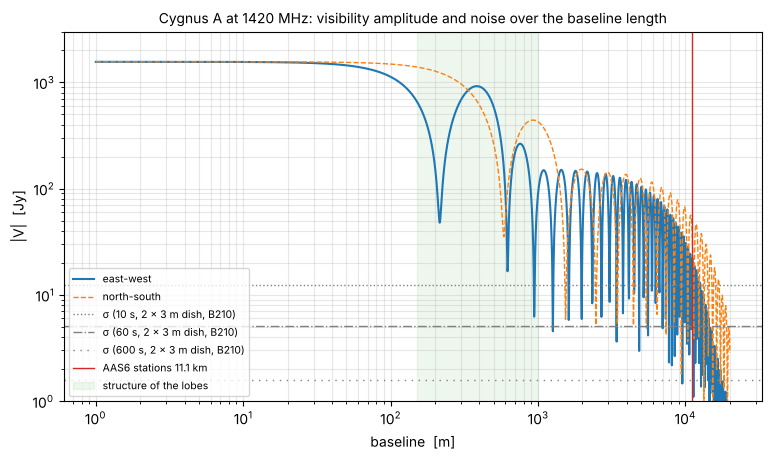

baseline [m]  |V| E-W [Jy]  |V| N-S [Jy]  S/N E-W (10 s)
          10        1551.4        1555.2           125.6
          50        1442.3        1537.2           116.8
         100        1124.3        1481.6            91.0
         200         158.7        1271.9            12.8
         300         682.4         964.2            55.2
         500         584.8         262.8            47.3
       1,000          90.0         424.3             7.3
       2,000          32.0         151.5             2.6
      11,093          21.3          38.8             1.7


In [9]:
cyga = SKIES["cyg_a"]
dish_arr = ARRAYS["aas6_sim_stations"]
d = dish_arr.stations[0].antenna
b = np.logspace(0, np.log10(2e4), 2000)                   # baseline in m
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.loglog(b, abs(cyga.visibility(b / lam, 0)), label="east-west")
ax.loglog(b, abs(cyga.visibility(0, b / lam)), "--", lw=1, label="north-south")
for t, ls in ((10, ":"), (60, "-."), (600, (0, (1, 4)))):
    ax.axhline(b210.baseline_sigma_jy(d, d, t), color="grey", ls=ls, lw=1,
               label=f"σ ({t:g} s, 2 × 3 m dish, B210)")
ax.axvline(dish_arr.baseline_lengths_m()[0], color="C3", lw=1, label="AAS6 stations 11.1 km")
ax.axvspan(150, 1000, color="C2", alpha=0.08, label="structure of the lobes")
ax.set_xlabel("baseline  [m]"); ax.set_ylabel("|V|  [Jy]"); ax.set_ylim(1, 3000)
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=7.5, loc="lower left")
ax.set_title("Cygnus A at 1420 MHz: visibility amplitude and noise over the baseline length", fontsize=10)
plt.show()
print(f"{'baseline [m]':>12s} {'|V| E-W [Jy]':>13s} {'|V| N-S [Jy]':>13s} {'S/N E-W (10 s)':>15s}")
for bl in (10, 50, 100, 200, 300, 500, 1000, 2000, dish_arr.baseline_lengths_m()[0]):
    ve, vn = abs(cyga.visibility(bl / lam, 0)), abs(cyga.visibility(0, bl / lam))
    print(f"{bl:12,.0f} {ve:13.1f} {vn:13.1f} {ve / b210.baseline_sigma_jy(d, d, 10):15.1f}")

## 4. Arrays

Station positions in the local frame (east, north) of the site and all baselines. Stations are given geodetically (AAS6 simulation, from `sb_iq_sim_a/b.json`) or as offsets in metres from the site (two horns).

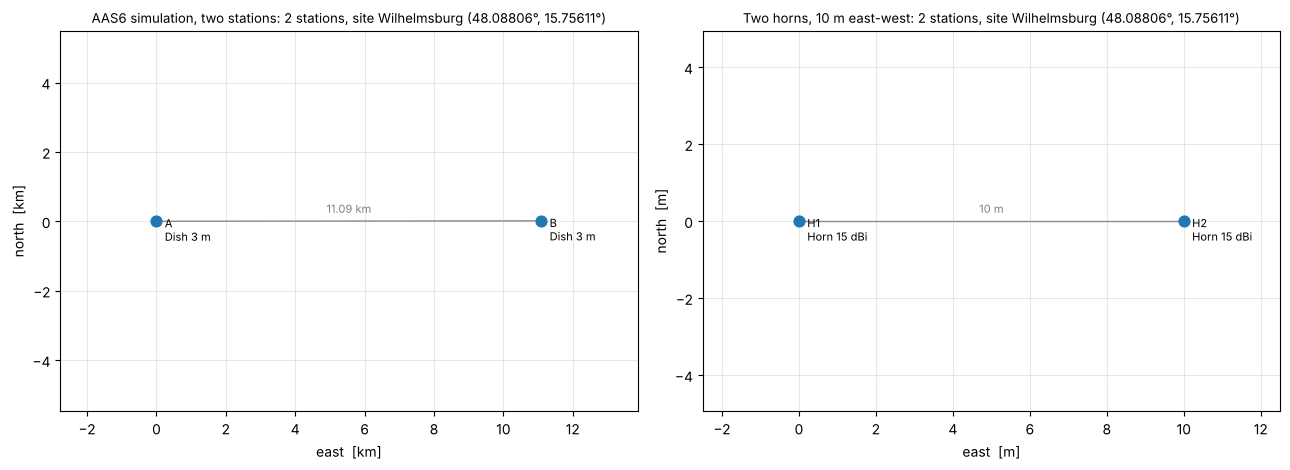

AAS6 simulation, two stations      A-B    east    11092.777 m  north    10.726 m  up   -9.628 m
Two horns, 10 m east-west          H1-H2  east       10.000 m  north    -0.000 m  up   -0.000 m


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, arr in zip(axes, ARRAYS.values()):
    plot_array(arr, ax=ax)
fig.tight_layout(); plt.show()
for arr in ARRAYS.values():
    for name, (e, n, u) in zip(arr.baseline_names(), arr.baselines_enu()):
        print(f"{arr.name:<34s} {name:6s} east {e:12.3f} m  north {n:9.3f} m  up {u:8.3f} m")

The AAS6 stations lie on the same latitude: the baseline is almost purely east–west; the small *up* component is the curvature of the Earth over 11 km.

## 5. Selector

Choose antenna, spectral line and integration time; the key figures, the SEFD and the noise of one baseline of two equal antennas with the B210 are shown together with the beam. (The selector needs a running kernel.)

In [11]:
import ipywidgets as widgets
from IPython.display import display

def show_antenna(key, line, t_int_s):
    a, f = ANTENNAS[key], LINES[line]
    s = a.summary(f)
    print(f"{a.name} at {line} ({f / 1e6:.3f} MHz)")
    print(f"  gain {s['gain_dbi']:.2f} dBi, A_eff {s['a_eff_m2']:.3f} m², HPBW {s['hpbw_deg']:.2f}°")
    print(f"  SEFD with {b210.name}: {b210.sefd_jy(a, f):,.0f} Jy")
    print(f"  noise of one visibility ({t_int_s:g} s, {b210.bandwidth_hz / 1e6:g} MHz): "
          f"{b210.baseline_sigma_jy(a, a, t_int_s, f):,.2f} Jy")
    plot_beams([a], f)
    plt.show()

display(widgets.interactive(
    show_antenna,
    key=widgets.Dropdown(options=list(ANTENNAS), value="dish_3m", description="antenna"),
    line=widgets.Dropdown(options=list(LINES), value="HI", description="line"),
    t_int_s=widgets.FloatLogSlider(value=10, base=10, min=-1, max=3, description="t_int [s]"),
))

interactive(children=(Dropdown(description='antenna', options=('dish_3m', 'horn_15dbi', 'yagi'), value='dish_3…